# Solar Filament Segmentation - v3
Changes vs v2: **continues training from `work/model_v2.pt`** (no restart), larger training crops (more context), flip TTA on CPU,
and a much better post-processing search (adds a per-filament confidence filter, wider grid, cached IoUs so the search is fast).
Written **`submission_v3.csv`**

%pip install -q segmentation-models-pytorch pycocotools opencv-python-headless pandas numpy tqdm

In [1]:
# 2) CONFIG
import os, json, glob, time, zipfile, itertools, csv, math
from collections import defaultdict
import numpy as np, cv2, pandas as pd, torch, torch.nn.functional as F
from tqdm.auto import tqdm
from pycocotools import mask as mu
import segmentation_models_pytorch as smp

ZIP_PATH = r"C:\Users\shrut\Desktop\final\filament-segmentation-2026.zip"
WORK_DIR = "./work"
RESUME_FROM = os.path.join(WORK_DIR, "model_v2.pt")   # set to None to train from scratch
TIME_BUDGET_MIN = None   # training minutes. None = auto (CPU 25, GPU 15)
SEED = 0                 # keep 0: same train/val split as v2, so the resumed model has not seen the val images

device = "cuda" if torch.cuda.is_available() else "cpu"
RES, EVAL_RES = 1024, 512
if device == "cuda":
    ENCODER, CROP, BS, BUDGET = "resnet34", 512, 8, (TIME_BUDGET_MIN or 15)*60
else:
    ENCODER, CROP, BS, BUDGET = "resnet18", 320, 6, (TIME_BUDGET_MIN or 25)*60
    torch.set_num_threads(os.cpu_count())
TTA = True               # horizontal-flip test-time augmentation (set False to halve inference time)
use_amp = device == "cuda"
print("device:", device, "| encoder", ENCODER, "| crop", CROP, "| train min:", BUDGET/60)
rng = np.random.default_rng(SEED); torch.manual_seed(SEED)

c:\Users\shrut\Desktop\final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | encoder resnet18 | crop 320 | train min: 25.0


In [2]:
# 3) unzip + locate files
data_dir = os.path.join(WORK_DIR, "data")
if not os.path.isdir(data_dir):
    os.makedirs(data_dir, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(data_dir)
ann_path = glob.glob(os.path.join(data_dir, "**", "*Annotations*train*.json"), recursive=True)[0]
train_dir = [d for d in glob.glob(os.path.join(data_dir, "**", "train_images"), recursive=True) if os.path.isdir(d)][0]
test_dir  = [d for d in glob.glob(os.path.join(data_dir, "**", "test_images"),  recursive=True) if os.path.isdir(d)][0]
get_stem = lambda p: os.path.splitext(os.path.basename(p))[0][-16:]
train_files = {get_stem(p): p for p in glob.glob(os.path.join(train_dir, "*"))}
test_files  = {get_stem(p): p for p in sorted(glob.glob(os.path.join(test_dir, "*")))}
print(len(train_files), "train files,", len(test_files), "test files")

707 train files, 180 test files


In [3]:
# 4) dataset. Inputs = 2 channels: raw intensity + local contrast (image minus large-scale blur, removes limb darkening)
def make_inputs(gray, res=RES):
    x = cv2.resize(gray, (res, res), interpolation=cv2.INTER_AREA)
    blur = cv2.GaussianBlur(x.astype(np.float32), (0, 0), 30)
    d = np.clip((x.astype(np.float32) - blur) * 2 + 128, 0, 255).astype(np.uint8)
    return x, d

def to_tensor(x, d):   # uint8 arrays (..., H, W) -> float tensor (N, 2, H, W)
    x = torch.from_numpy(np.ascontiguousarray(x)).float(); d = torch.from_numpy(np.ascontiguousarray(d)).float()
    return torch.stack([(x/255 - 0.45)/0.25, (d - 128)/2/40], 1)

coco = json.load(open(ann_path))
anns_by_img = defaultdict(list)
for a in coco["annotations"]: anns_by_img[a["image_id"]].append(a)
groups = defaultdict(list)
for im in coco["images"]:
    s = get_stem(im["file_name"])
    if s in train_files: groups[s].append(im)
for s in groups: groups[s].sort(key=lambda d: str(d["id"]))
stems = sorted(groups); print("unique train images:", len(stems))
perm = rng.permutation(len(stems)); n_val = max(8, int(0.15*len(stems)))
val_stems = [stems[i] for i in perm[:n_val]]; tr_stems = [stems[i] for i in perm[n_val:]]

def poly_masks(img_info, res):   # one binary mask per filament, at resolution res
    sc = res / img_info["width"]; inst = []
    for a in anns_by_img[img_info["id"]]:
        m = np.zeros((res, res), np.uint8)
        for seg in a["segmentation"]:
            cv2.fillPoly(m, [np.round(np.array(seg, dtype=np.float64).reshape(-1, 2) * sc).astype(np.int32)], 1)
        inst.append(m)
    return inst

def union_soft(s, res):   # mean over annotators of their union mask, stored as uint8 0..255
    ms = []
    for im in groups[s]:
        p = poly_masks(im, res)
        ms.append(np.clip(np.sum(p, 0), 0, 1) if p else np.zeros((res, res), np.uint8))
    return np.round(np.mean(ms, 0) * 255).astype(np.uint8)

def read_gray(path): return cv2.imread(path, cv2.IMREAD_GRAYSCALE)

Xtr, Dtr, Ytr = [], [], []
for s in tqdm(tr_stems):
    x, d = make_inputs(read_gray(train_files[s])); Xtr.append(x); Dtr.append(d); Ytr.append(union_soft(s, RES))
Xtr, Dtr, Ytr = np.stack(Xtr), np.stack(Dtr), np.stack(Ytr)
fg_idx = [np.flatnonzero(y.ravel() > 127) for y in Ytr]   # foreground pixels, used to centre crops on filaments

Xva, Dva, GTva = [], [], []
for s in tqdm(val_stems):
    x, d = make_inputs(read_gray(train_files[s])); Xva.append(x); Dva.append(d)
    GTva.append([[m.astype(bool) for m in poly_masks(im, EVAL_RES)] for im in groups[s]])   # one instance list per annotator
Xva, Dva = np.stack(Xva), np.stack(Dva)
print(Xtr.shape, Xva.shape)

unique train images: 707


100%|██████████| 106/106 [00:05<00:00, 19.88it/s]


(601, 1024, 1024) (106, 1024, 1024)


In [4]:
# 5) model (warm start from v2 if available) + training on random crops
resume = RESUME_FROM is not None and os.path.exists(RESUME_FROM)
if resume:
    model = smp.Unet(ENCODER, encoder_weights=None, in_channels=2, classes=1)
    model.load_state_dict(torch.load(RESUME_FROM, map_location="cpu")); BASE_LR = 2e-4
    print("resumed from", RESUME_FROM)
else:
    try:
        model = smp.Unet(ENCODER, encoder_weights="imagenet", in_channels=2, classes=1); print("loaded ImageNet encoder")
    except Exception as e:
        print("pretrained weights unavailable -> from scratch"); model = smp.Unet(ENCODER, encoder_weights=None, in_channels=2, classes=1)
    BASE_LR = 5e-4
model.to(device)

def get_batch():
    xs, ds, ys = [], [], []
    for _ in range(BS):
        i = int(rng.integers(len(Xtr)))
        if rng.random() < 0.8 and len(fg_idx[i]):
            p = int(fg_idx[i][rng.integers(len(fg_idx[i]))]); cy, cx = divmod(p, RES)
            y0 = int(np.clip(cy - CROP//2 + rng.integers(-CROP//4, CROP//4 + 1), 0, RES - CROP))
            x0 = int(np.clip(cx - CROP//2 + rng.integers(-CROP//4, CROP//4 + 1), 0, RES - CROP))
        else:
            y0, x0 = int(rng.integers(0, RES - CROP + 1)), int(rng.integers(0, RES - CROP + 1))
        sl = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))
        a, b, c = Xtr[i][sl], Dtr[i][sl], Ytr[i][sl]
        if rng.random() < .5: a, b, c = a[:, ::-1], b[:, ::-1], c[:, ::-1]
        if rng.random() < .5: a, b, c = a[::-1], b[::-1], c[::-1]
        k = int(rng.integers(4)); a, b, c = np.rot90(a, k), np.rot90(b, k), np.rot90(c, k)
        xs.append(a); ds.append(b); ys.append(c)
    t = to_tensor(np.stack(xs), np.stack(ds))
    t[:, 0] = t[:, 0] * float(rng.uniform(0.9, 1.1)) + float(rng.uniform(-0.1, 0.1))
    return t.to(device), (torch.from_numpy(np.stack(ys)).float() / 255).unsqueeze(1).to(device)

def loss_fn(lg, y):
    bce = F.binary_cross_entropy_with_logits(lg, y)
    p = torch.sigmoid(lg); inter = (p*y).sum((1,2,3))
    dice = 1 - (2*inter + 1) / (p.sum((1,2,3)) + y.sum((1,2,3)) + 1)
    return bce + dice.mean()

opt = torch.optim.AdamW(model.parameters(), lr=BASE_LR, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
t0 = time.time(); it = 0; run = []
model.train()
while True:
    frac = (time.time() - t0) / BUDGET
    if frac >= 1: break
    for g in opt.param_groups: g["lr"] = BASE_LR * (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * frac)))
    x, y = get_batch()
    with torch.autocast(device_type=device, enabled=use_amp):
        lg = model(x)
    loss = loss_fn(lg.float(), y)
    opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    run.append(loss.item()); it += 1
    if it % 50 == 0:
        print(f"iter {it} | loss {np.mean(run[-50:]):.4f} | {(time.time()-t0)/60:.1f}/{BUDGET/60:.0f} min")
torch.save(model.state_dict(), os.path.join(WORK_DIR, "model_v3.pt")); print("trained", it, "iterations")

resumed from ./work\model_v2.pt


C:\Users\shrut\AppData\Local\Temp\ipykernel_11764\3194013832.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


iter 50 | loss 0.4302 | 1.1/25 min
iter 100 | loss 0.3990 | 2.1/25 min
iter 150 | loss 0.4210 | 3.2/25 min
iter 200 | loss 0.4018 | 4.3/25 min
iter 250 | loss 0.4111 | 5.4/25 min
iter 300 | loss 0.4002 | 6.6/25 min
iter 350 | loss 0.3865 | 7.7/25 min
iter 400 | loss 0.3906 | 8.8/25 min
iter 450 | loss 0.3685 | 9.9/25 min
iter 500 | loss 0.3704 | 11.0/25 min
iter 550 | loss 0.3770 | 12.2/25 min
iter 600 | loss 0.3763 | 13.3/25 min
iter 650 | loss 0.3574 | 14.5/25 min
iter 700 | loss 0.3799 | 15.6/25 min
iter 750 | loss 0.3608 | 16.8/25 min
iter 800 | loss 0.3661 | 18.0/25 min
iter 850 | loss 0.3583 | 19.2/25 min
iter 900 | loss 0.3566 | 20.4/25 min
iter 950 | loss 0.3607 | 22.2/25 min
iter 1000 | loss 0.3534 | 23.2/25 min
iter 1050 | loss 0.3608 | 24.2/25 min
trained 1089 iterations


In [5]:
# 6) full-image inference (1024px) + validation probabilities
@torch.no_grad()
def predict_probs(X, D, bs=2):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x = to_tensor(X[i:i+bs], D[i:i+bs]).to(device)
        with torch.autocast(device_type=device, enabled=use_amp):
            p = torch.sigmoid(model(x).float())
            if TTA: p = (p + torch.sigmoid(model(x.flip(-1)).float()).flip(-1)) / 2
        out.append(p.squeeze(1).cpu().numpy())
    return np.concatenate(out)

Pva_full = predict_probs(Xva, Dva)
Pva = np.stack([cv2.resize(p, (EVAL_RES, EVAL_RES), interpolation=cv2.INTER_AREA) for p in Pva_full])

In [6]:
# 7) post-processing: components with confidence score, cached IoUs, wide fast grid search
def get_components(prob, thr, k, s=1.0):
    m = (prob > thr).astype(np.uint8)
    kk = int(round(k * s))
    if kk > 1: m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kk, kk)))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)   # fill holes
    m = np.zeros_like(m); cv2.drawContours(m, cnts, -1, 1, thickness=-1)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    return [(lab == i, int(stats[i, cv2.CC_STAT_AREA]), float(prob[lab == i].mean())) for i in range(1, n)]

def select(comps, min_area, min_score, s=1.0):
    return [c for c in comps if c[1] >= min_area * s * s and c[2] >= min_score]

def iou_mats(comps, annots):   # one (n_gt x n_pred) IoU matrix per annotator, computed once per (thr, k)
    nP = len(comps); out = []
    P = np.stack([c[0].ravel() for c in comps]).astype(np.float32) if nP else None
    for gts in annots:
        if nP and gts:
            G = np.stack([g.ravel() for g in gts]).astype(np.float32); inter = G @ P.T
            out.append(inter / (G.sum(1)[:, None] + P.sum(1)[None] - inter + 1e-9))
        else: out.append(np.zeros((len(gts), nP), np.float32))
    return out

# GT statistics, to sanity-check how many filaments to expect
n_gt = np.mean([len(g) for a in GTva for g in a]); print("GT filaments per image (per annotator): %.1f" % n_gt)

THRS, KS = [0.3, 0.4, 0.5, 0.6, 0.7], [0, 5, 9, 15, 25, 35]
MAS, MSS = [20, 40, 80, 150, 300, 600], [0.0, 0.5, 0.6, 0.7, 0.8]
results = []
for thr in tqdm(THRS):
    for k in KS:
        cache = []
        for prob, annots in zip(Pva, GTva):
            comps = get_components(prob, thr, k)
            cache.append((np.array([c[1] for c in comps]), np.array([c[2] for c in comps]), iou_mats(comps, annots)))
        for ma in MAS:
            for ms in MSS:
                s_iou = tp = fp = fn = 0
                for areas, scores, mats in cache:
                    keepm = (areas >= ma) & (scores >= ms) if len(areas) else np.zeros(0, bool)
                    npred = int(keepm.sum())
                    for iou in mats:
                        sub = iou[:, keepm]; mt = sub > 0.5; t = int(mt.sum())
                        s_iou += float(sub[mt].sum()); tp += t; fp += npred - t; fn += iou.shape[0] - t
                results.append((s_iou / max(tp + .5*fp + .5*fn, 1e-9), thr, k, ma, ms))
results.sort(reverse=True)
print("top 5 (PQ, thr, close_k, min_area, min_score):"); [print("  %.4f %s %s %s %s" % r) for r in results[:5]]
BEST_PQ, THR, K, MINA, MINS = results[0]
print("best val PQ: %.4f" % BEST_PQ)

GT filaments per image (per annotator): 7.2


100%|██████████| 5/5 [01:32<00:00, 18.58s/it]

top 5 (PQ, thr, close_k, min_area, min_score):
  0.3866 0.3 0 40 0.8
  0.3864 0.3 0 20 0.8
  0.3777 0.3 0 40 0.7
  0.3768 0.3 15 40 0.7
  0.3754 0.3 5 20 0.8
best val PQ: 0.3866


In [7]:
# 8) predict test set -> submission_v3.csv
rows = []; n_img_with = 0
for stem, path in tqdm(test_files.items()):
    g = read_gray(path); H, W = g.shape
    x, d = make_inputs(g)
    prob = cv2.resize(predict_probs(x[None], d[None])[0], (W, H), interpolation=cv2.INTER_LINEAR)
    s = W / EVAL_RES
    insts = select(get_components(prob, THR, K, s), MINA, MINS, s)
    if not insts:   # fallback: biggest blob at a lower threshold
        insts = sorted(get_components(prob, 0.2, 0, s), key=lambda c: -c[1])[:1]
    n_img_with += bool(insts)
    for i, c in enumerate(insts, 1):
        r = mu.encode(np.asfortranarray(c[0].astype(np.uint8)))
        rows.append((f"{stem}_{i}", r["counts"].decode()))
sub = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
sub.to_csv("submission_v3.csv", index=False, quoting=csv.QUOTE_NONE)
print(len(sub), "filaments (%.1f per image) over" % (len(sub)/len(test_files)), n_img_with, "/", len(test_files), "images -> submission_v3.csv")
sub.head()

  0%|          | 0/180 [00:00<?, ?it/s]

100%|██████████| 180/180 [04:55<00:00,  1.64s/it]


1372 filaments (7.6 per image) over 180 / 180 images -> submission_v3.csv


,filament_id,segmentation_rle
0,20110120105534Ch_1,n_Ti22lo15L3N2O0O1jPNGdn19[QNHen19YQNHfn1:YQNE...
1,20110120105534Ch_2,jjVo18go11O100O1O10OO101O001O00O2K41O101N3N1N1...
2,20110130110334Ch_1,^Xlm16go15H8M1O2N2O0O2N2O2N1N3N5K1O1O1N2JgNbQN...
3,20110130110334Ch_2,b_jd23jo19I3L6I5O2OO0001oPNYOgn1Q1OO2O00000O11...
4,20110214175414Mh_1,Y]b[24ho17K3J6L4M3N2O0O2POWOgRNi0Wm1[OfRNg0Ym1...


---
# Visualizations & analysis
Run these cells **after cell 7** (cell 8 is optional; the test-set figures read `submission_v3.csv` from disk).
All figures are also saved as PNG files in `./figures/`.

*If the kernel was restarted:* in cell 2 set `RESUME_FROM = "./work/model_v3.pt"` and `TIME_BUDGET_MIN = 0.05`, then run cells 2-7 and these cells.

In [8]:
%pip install -q matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
# V1) setup, helpers and validation metrics with the final (tuned) post-processing
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
def savefig(name): plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def overlay(img, masks, alpha=0.45):
    rgb = np.ascontiguousarray(np.stack([img] * 3, -1).astype(np.float32) / 255)
    cm = plt.get_cmap("tab10")
    for j, m in enumerate(masks):
        c = np.array(cm(j % 10)[:3], dtype=np.float32)
        rgb[m] = (1 - alpha) * rgb[m] + alpha * c
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cnts, -1, tuple(float(v) for v in c), 1)
    return rgb

def crop_box(masks, shape, pad=40, min_side=200):
    H, W = shape; allm = np.zeros(shape, bool)
    for m in masks: allm |= m
    ys, xs = np.where(allm)
    if len(ys) == 0: return 0, H, 0, W
    side = int(min(max(ys.max() - ys.min(), xs.max() - xs.min()) + 2 * pad, H)); side = max(side, min(min_side, H))
    cy, cx = (ys.min() + ys.max()) // 2, (xs.min() + xs.max()) // 2
    y0 = int(np.clip(cy - side // 2, 0, H - side)); x0 = int(np.clip(cx - side // 2, 0, W - side))
    return y0, y0 + side, x0, x0 + side

# final predictions on the validation images, with the tuned parameters
val_preds = [select(get_components(p, THR, K), MINA, MINS) for p in Pva]
rows_v = []
for i, (comps, annots) in enumerate(zip(val_preds, GTva)):
    mats = iou_mats(comps, annots)
    pu = np.zeros((EVAL_RES, EVAL_RES), bool)
    for c in comps: pu |= c[0]
    pqs, dices, ious, o2m, m2o, TP, FP, FN = [], [], [], 0, 0, 0, 0, 0
    for gts, iou in zip(annots, mats):
        mt = iou > 0.5; tp = int(mt.sum()); fp = len(comps) - tp; fn = len(gts) - tp
        if tp + .5*fp + .5*fn > 0: pqs.append(float(iou[mt].sum()) / (tp + .5*fp + .5*fn))
        ious += [float(v) for v in iou[mt]]
        gu = np.zeros_like(pu)
        for g_ in gts: gu |= g_
        if gu.sum() + pu.sum() > 0: dices.append(2 * (gu & pu).sum() / (gu.sum() + pu.sum()))
        ov = iou > 0.1; o2m += int((ov.sum(1) > 1).sum()); m2o += int((ov.sum(0) > 1).sum())
        TP += tp; FP += fp; FN += fn
    rows_v.append(dict(img=i, pq=np.mean(pqs) if pqs else np.nan, dice=np.mean(dices) if dices else np.nan,
                       ious=ious, o2m=o2m, m2o=m2o, tp=TP, fp=FP, fn=FN))
vm = pd.DataFrame(rows_v)
all_ious = np.array([v for r in rows_v for v in r["ious"]])
summary = pd.Series({
    "Validation PQ (tuned, dataset-level)": BEST_PQ,
    "Mean per-image PQ": vm.pq.mean(),
    "Mean per-image Dice (pixel)": vm.dice.mean(),
    "Mean IoU of matched filaments": all_ious.mean() if len(all_ious) else np.nan,
    "True positives": int(vm.tp.sum()), "False positives": int(vm.fp.sum()), "False negatives": int(vm.fn.sum()),
    "One-to-many (GT split into >1 predictions)": int(vm.o2m.sum()),
    "Many-to-one (>1 GT merged into one prediction)": int(vm.m2o.sum())})
print("Tuned parameters: threshold=%s, closing=%s px, min area=%s px, min score=%s (at %dpx scale)" % (THR, K, MINA, MINS, EVAL_RES))
summary.to_frame("value").style.format(precision=3) if False else print(summary.round(3).to_string())

Tuned parameters: threshold=0.3, closing=0 px, min area=40 px, min score=0.8 (at 512px scale)
Validation PQ (tuned, dataset-level)                0.387
Mean per-image PQ                                   0.368
Mean per-image Dice (pixel)                         0.614
Mean IoU of matched filaments                       0.659
True positives                                    711.000
False positives                                   507.000
False negatives                                   496.000
One-to-many (GT split into >1 predictions)         47.000
Many-to-one (>1 GT merged into one prediction)     20.000


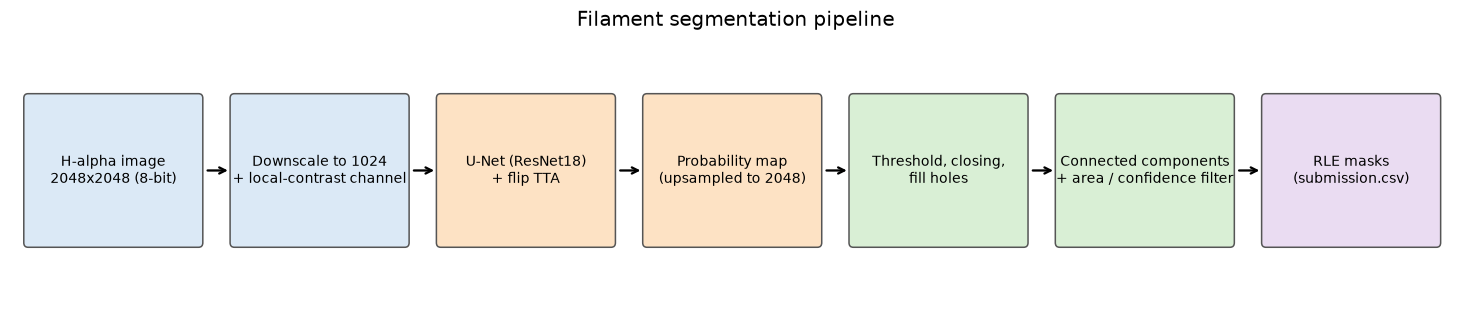

In [10]:
# V2) Pipeline diagram
fig, ax = plt.subplots(figsize=(17, 3.2)); ax.axis("off"); ax.set_xlim(0, 17); ax.set_ylim(0, 3)
steps = ["H-alpha image\n2048x2048 (8-bit)", "Downscale to 1024\n+ local-contrast channel", "U-Net (ResNet18)\n+ flip TTA",
         "Probability map\n(upsampled to 2048)", "Threshold, closing,\nfill holes", "Connected components\n+ area / confidence filter", "RLE masks\n(submission.csv)"]
cols = ["#dbe9f6", "#dbe9f6", "#fde2c4", "#fde2c4", "#d9efd5", "#d9efd5", "#eadcf2"]
for j, (t_, c_) in enumerate(zip(steps, cols)):
    x0_ = 0.2 + j * 2.42
    ax.add_patch(plt.matplotlib.patches.FancyBboxPatch((x0_, 0.7), 2.0, 1.6, boxstyle="round,pad=0.05", fc=c_, ec="#555"))
    ax.text(x0_ + 1.0, 1.5, t_, ha="center", va="center", fontsize=9)
    if j < len(steps) - 1: ax.annotate("", xy=(x0_ + 2.38, 1.5), xytext=(x0_ + 2.07, 1.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_title("Filament segmentation pipeline", fontsize=13)
savefig("01_pipeline"); plt.show()

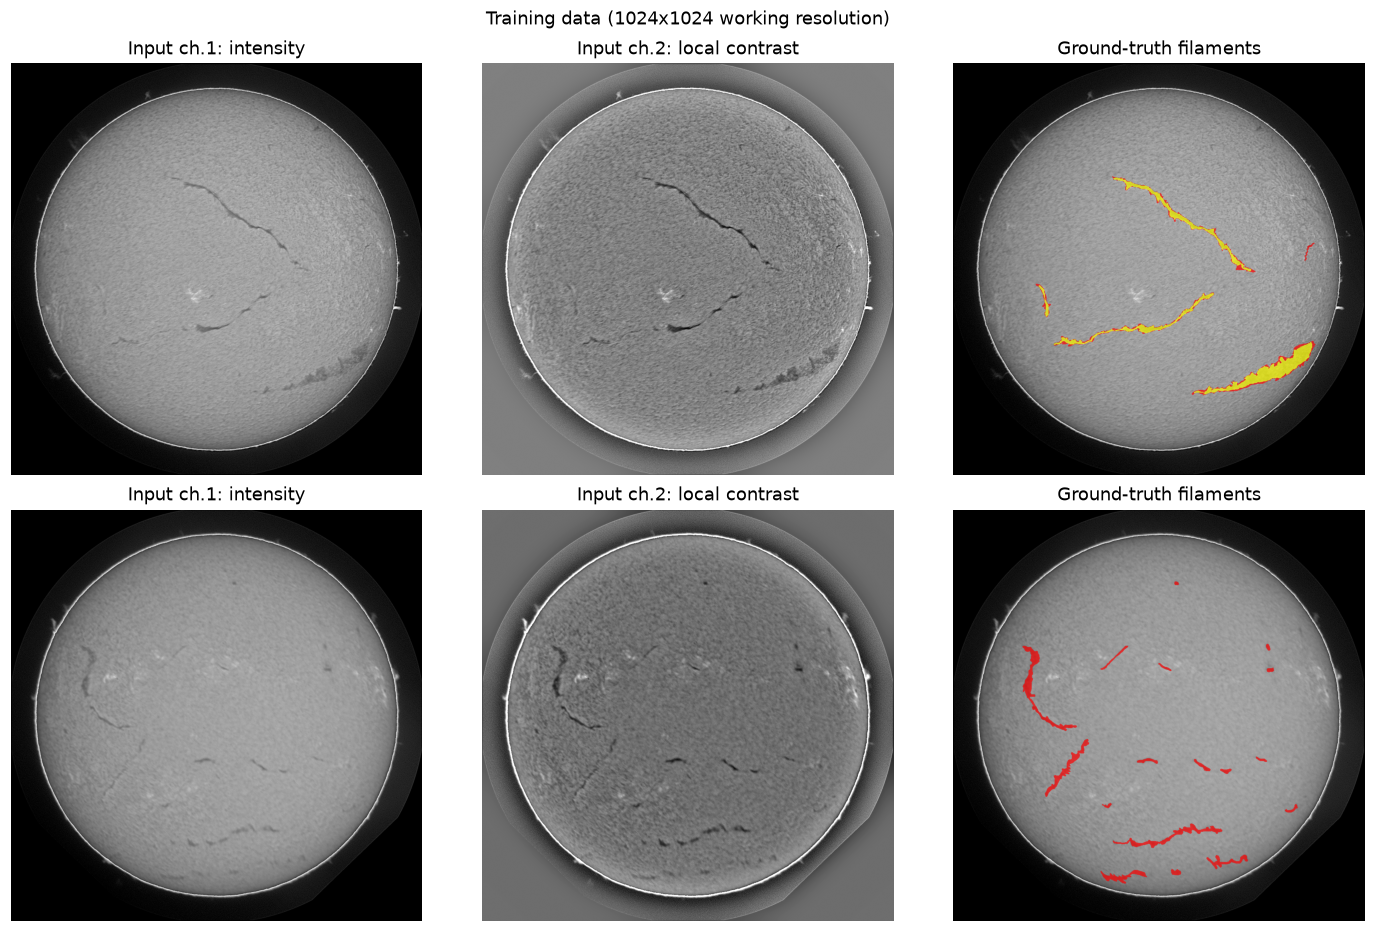

In [11]:
# V3) Training data: input channels and ground-truth target
order = np.argsort([-int((y > 127).sum()) for y in Ytr])[::max(1, len(Ytr)//40)][:2]
fig, axs = plt.subplots(2, 3, figsize=(13, 8.6))
for r, i in enumerate(order):
    axs[r, 0].imshow(Xtr[i], cmap="gray"); axs[r, 0].set_title("Input ch.1: intensity")
    axs[r, 1].imshow(Dtr[i], cmap="gray"); axs[r, 1].set_title("Input ch.2: local contrast")
    axs[r, 2].imshow(Xtr[i], cmap="gray"); axs[r, 2].imshow(np.ma.masked_less(Ytr[i], 30), cmap="autumn", alpha=0.7); axs[r, 2].set_title("Ground-truth filaments")
for a in axs.ravel(): a.axis("off")
plt.suptitle("Training data (1024x1024 working resolution)"); plt.tight_layout(); savefig("02_training_data"); plt.show()

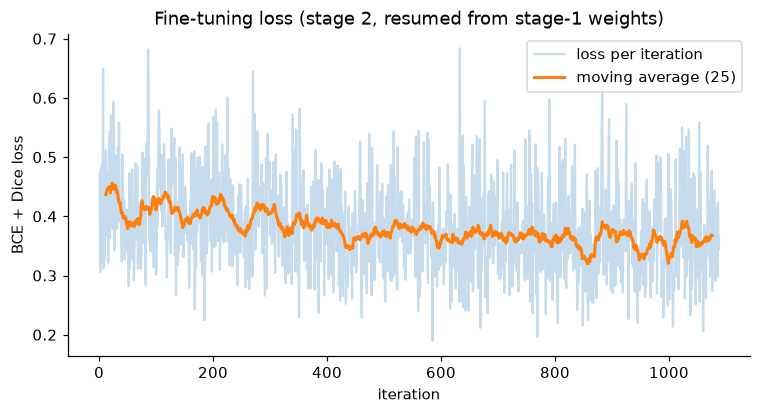

In [12]:
# V4) Training loss
L = np.array(run); w = min(25, max(1, len(L)//5)); sm = np.convolve(L, np.ones(w)/w, mode="valid")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(L, alpha=0.25, label="loss per iteration"); ax.plot(np.arange(len(sm)) + w//2, sm, lw=2, label=f"moving average ({w})")
ax.set_xlabel("iteration"); ax.set_ylabel("BCE + Dice loss"); ax.set_title("Fine-tuning loss (stage 2, resumed from stage-1 weights)"); ax.legend()
savefig("03_training_loss"); plt.show()

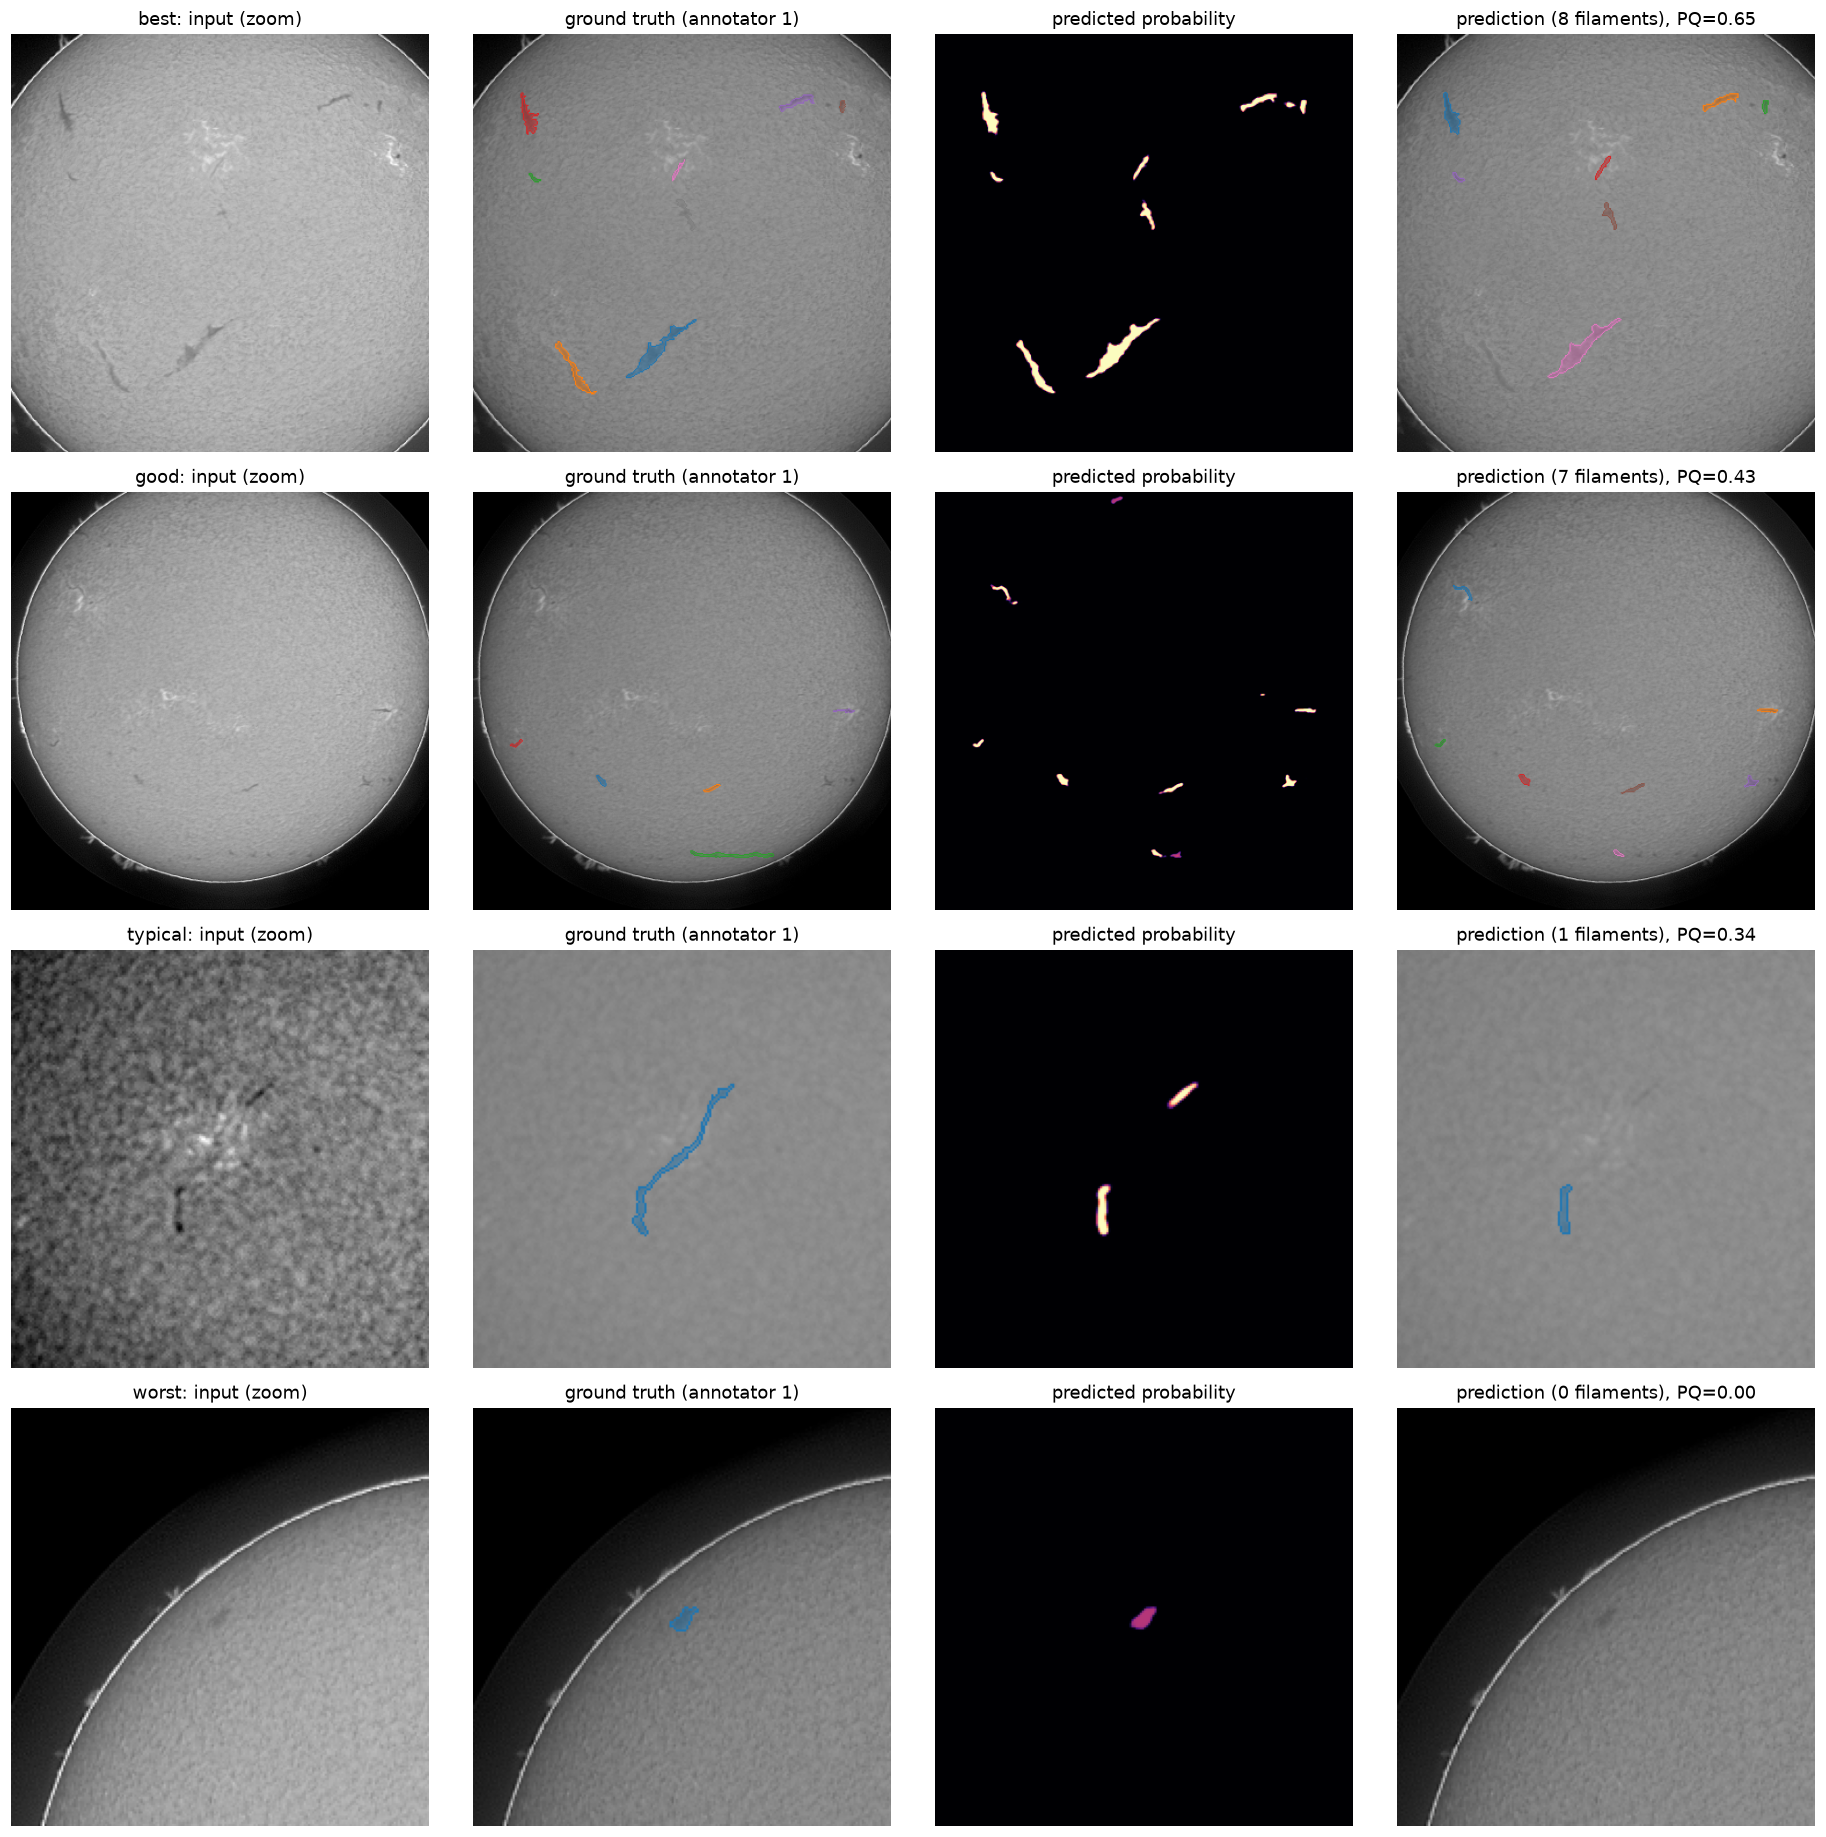

In [13]:
# V5) Qualitative results on held-out validation images (best / typical / worst), zoomed to the filament region
valid = vm.dropna(subset=["pq"]).sort_values("pq")
pick = [valid.img.iloc[-1], valid.img.iloc[len(valid)*2//3], valid.img.iloc[len(valid)//3], valid.img.iloc[0]]
tags = ["best", "good", "typical", "worst"]
fig, axs = plt.subplots(len(pick), 4, figsize=(17, 4.2 * len(pick)))
for r, (i, tag) in enumerate(zip(pick, tags)):
    img = cv2.resize(Xva[i], (EVAL_RES, EVAL_RES), interpolation=cv2.INTER_AREA)
    gts = GTva[i][0]; preds = [c[0] for c in val_preds[i]]
    y0, y1, x0, x1 = crop_box(gts + preds, (EVAL_RES, EVAL_RES)); sl = (slice(y0, y1), slice(x0, x1))
    axs[r, 0].imshow(img[sl], cmap="gray"); axs[r, 0].set_title(f"{tag}: input (zoom)")
    axs[r, 1].imshow(overlay(img, gts)[sl]); axs[r, 1].set_title("ground truth (annotator 1)")
    axs[r, 2].imshow(Pva[i][sl], cmap="magma", vmin=0, vmax=1); axs[r, 2].set_title("predicted probability")
    axs[r, 3].imshow(overlay(img, preds)[sl]); axs[r, 3].set_title(f"prediction ({len(preds)} filaments), PQ={vm.pq[i]:.2f}")
    for a in axs[r]: a.axis("off")
plt.tight_layout(); savefig("04_validation_examples"); plt.show()

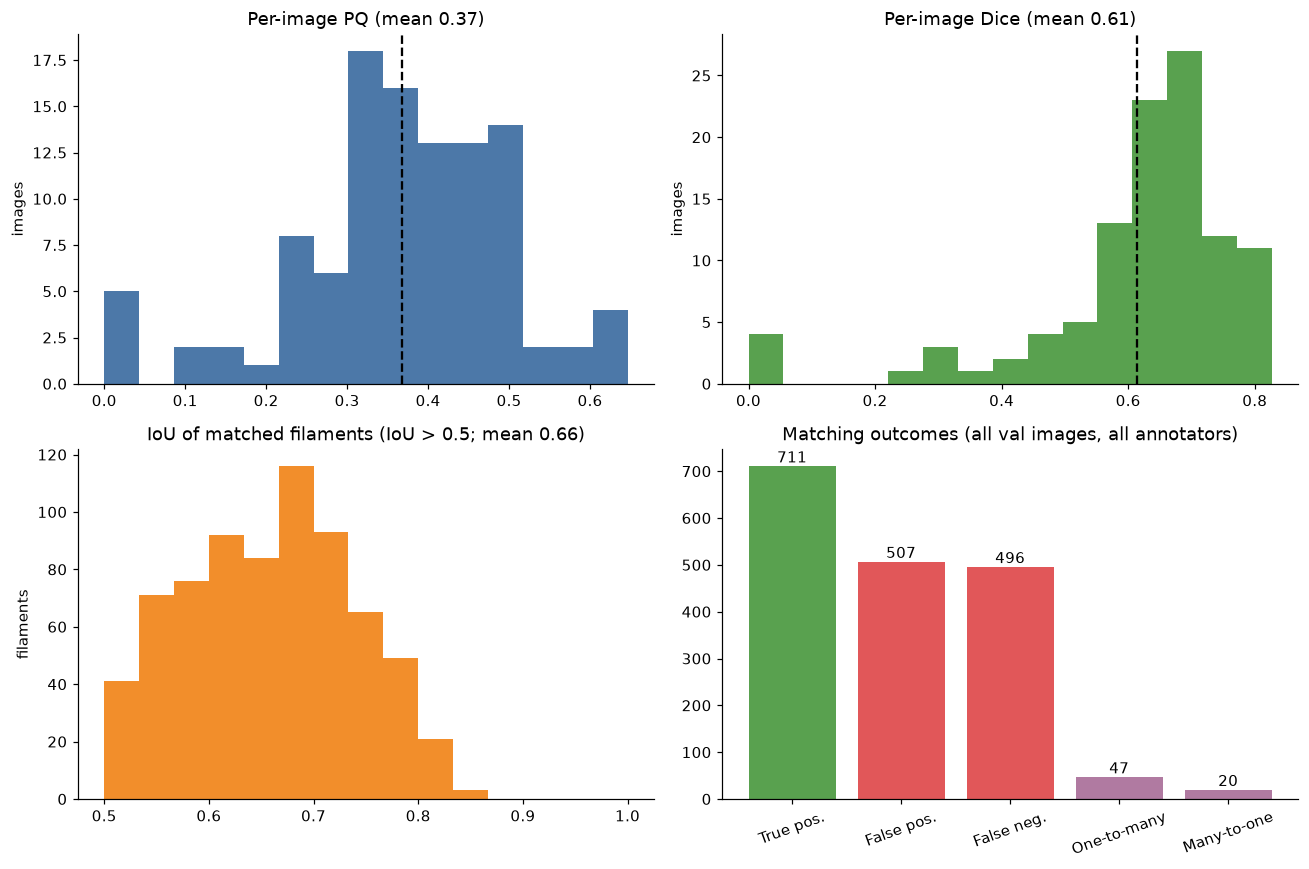

In [14]:
# V6) Validation metric distributions
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].hist(vm.pq.dropna(), bins=15, color="#4c78a8"); axs[0, 0].axvline(vm.pq.mean(), c="k", ls="--"); axs[0, 0].set_title("Per-image PQ (mean %.2f)" % vm.pq.mean())
axs[0, 1].hist(vm.dice.dropna(), bins=15, color="#59a14f"); axs[0, 1].axvline(vm.dice.mean(), c="k", ls="--"); axs[0, 1].set_title("Per-image Dice (mean %.2f)" % vm.dice.mean())
if len(all_ious): axs[1, 0].hist(all_ious, bins=15, range=(0.5, 1), color="#f28e2b"); axs[1, 0].set_title("IoU of matched filaments (IoU > 0.5; mean %.2f)" % all_ious.mean())
labels = ["True pos.", "False pos.", "False neg.", "One-to-many", "Many-to-one"]
vals = [vm.tp.sum(), vm.fp.sum(), vm.fn.sum(), vm.o2m.sum(), vm.m2o.sum()]
b = axs[1, 1].bar(labels, vals, color=["#59a14f", "#e15759", "#e15759", "#b07aa1", "#b07aa1"]); axs[1, 1].bar_label(b); axs[1, 1].set_title("Matching outcomes (all val images, all annotators)")
axs[1, 1].tick_params(axis="x", rotation=20)
for a in axs.ravel()[:3]: a.set_ylabel("images" if a is not axs[1, 0] else "filaments")
plt.tight_layout(); savefig("05_validation_distributions"); plt.show()

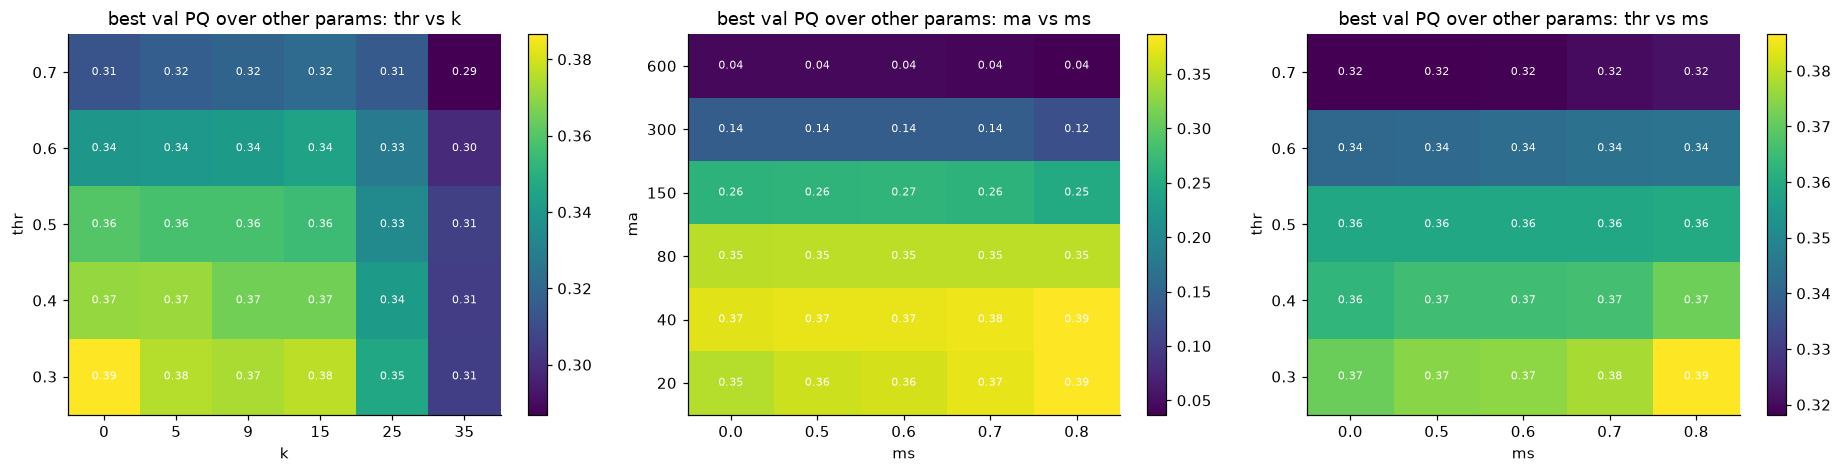

In [15]:
# V7) Post-processing parameter sensitivity (from the grid search in cell 7)
R = pd.DataFrame(results, columns=["pq", "thr", "k", "ma", "ms"])
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
for a, (r_, c_) in zip(axs, [("thr", "k"), ("ma", "ms"), ("thr", "ms")]):
    P_ = R.pivot_table(index=r_, columns=c_, values="pq", aggfunc="max")
    im_ = a.imshow(P_.values, cmap="viridis", aspect="auto", origin="lower")
    a.set_xticks(range(len(P_.columns))); a.set_xticklabels(P_.columns); a.set_yticks(range(len(P_.index))); a.set_yticklabels(P_.index)
    a.set_xlabel(c_); a.set_ylabel(r_); a.set_title(f"best val PQ over other params: {r_} vs {c_}")
    for (yy, xx), v in np.ndenumerate(P_.values): a.text(xx, yy, f"{v:.2f}", ha="center", va="center", color="w", fontsize=7)
    plt.colorbar(im_, ax=a)
plt.tight_layout(); savefig("06_parameter_sensitivity"); plt.show()

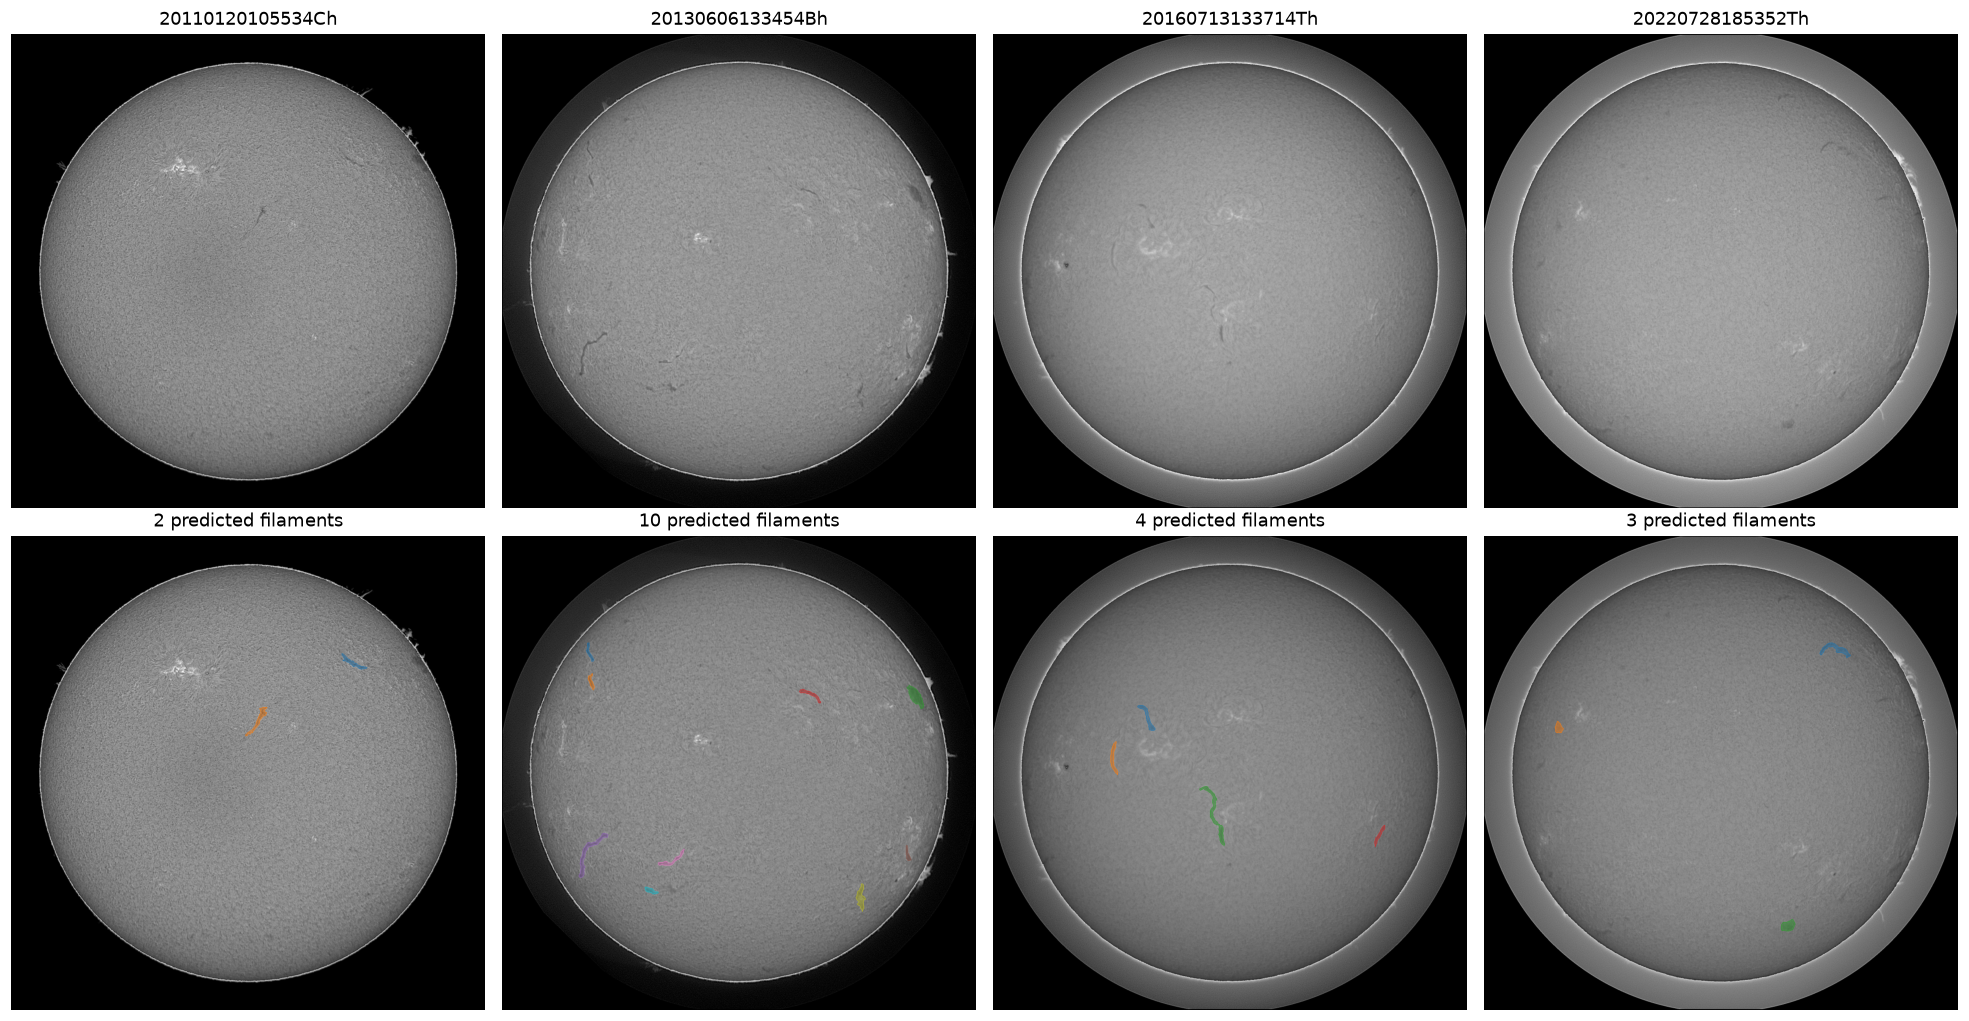

In [16]:
# V8) Test-set predictions (same pipeline as the submission) on 4 example images
tkeys = list(test_files)
sel = [tkeys[j] for j in np.linspace(0, len(tkeys) - 1, 4).astype(int)]
fig, axs = plt.subplots(2, 4, figsize=(18, 9.4))
for j, stem in enumerate(sel):
    g = read_gray(test_files[stem]); H, W = g.shape; xx_, dd_ = make_inputs(g)
    prob = cv2.resize(predict_probs(xx_[None], dd_[None])[0], (W, H), interpolation=cv2.INTER_LINEAR)
    s_ = W / EVAL_RES; insts = select(get_components(prob, THR, K, s_), MINA, MINS, s_)
    g_s = cv2.resize(g, (1024, 1024), interpolation=cv2.INTER_AREA)
    ms_ = [cv2.resize(c[0].astype(np.uint8), (1024, 1024), interpolation=cv2.INTER_NEAREST).astype(bool) for c in insts]
    axs[0, j].imshow(g_s, cmap="gray"); axs[0, j].set_title(stem)
    axs[1, j].imshow(overlay(g_s, ms_)); axs[1, j].set_title(f"{len(insts)} predicted filaments")
    axs[0, j].axis("off"); axs[1, j].axis("off")
plt.tight_layout(); savefig("07_test_predictions"); plt.show()

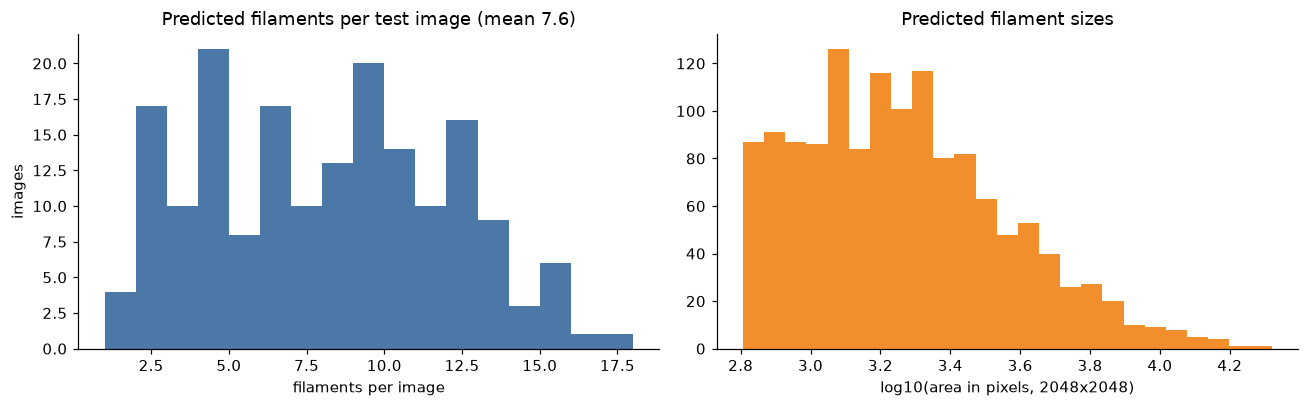

1372 filaments over 180 test images


In [17]:
# V9) Statistics of the final submission file
sdf = pd.read_csv("submission_v3.csv"); sdf["img"] = sdf.filament_id.str.rsplit("_", n=1).str[0]
areas = np.array([mu.area({"size": [2048, 2048], "counts": r.encode()}) for r in sdf.segmentation_rle])
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].hist(sdf.groupby("img").size(), bins=range(1, int(sdf.groupby("img").size().max()) + 2), color="#4c78a8"); axs[0].set_xlabel("filaments per image"); axs[0].set_ylabel("images")
axs[0].set_title("Predicted filaments per test image (mean %.1f)" % (len(sdf) / sdf.img.nunique()))
axs[1].hist(np.log10(areas), bins=25, color="#f28e2b"); axs[1].set_xlabel("log10(area in pixels, 2048x2048)"); axs[1].set_title("Predicted filament sizes")
plt.tight_layout(); savefig("08_submission_stats"); plt.show()
print(len(sdf), "filaments over", sdf.img.nunique(), "test images")